# 10 – Customer Value & Retention Prioritization (Simple Version)

**Goal:** identify customers who are valuable and may be at risk of leaving, then recommend a simple retention action.

**Steps:** Load data → calculate customer value → predict churn risk → rank customers → visualize → export.

This is a **portfolio prototype**. Customer value is a heuristic score, not a true lifetime value prediction. Churn probabilities are estimates from Notebook 09, not actual churn labels.

## 1. Imports and paths

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_path = root / 'data' / 'processed' / 'customer_features.csv'
model_path = root / 'models' / 'churn_pipeline.joblib'
output_path = root / 'data' / 'processed' / 'customer_retention_priority.csv'


## 2. Load and prepare data

Fill missing monthly charges with the median for financial calculations. Keep the original columns for the churn model.

In [2]:
df = pd.read_csv(data_path)
print('Dataset shape:', df.shape)

if df['customer_id'].isna().any() or df['customer_id'].duplicated().any():
    raise ValueError('customer_id must be present and unique')

# Save model inputs BEFORE creating any new analysis columns.
model_inputs = df.drop(columns=['customer_id', 'churn'])

df['monthly_charges_clean'] = df['monthly_charges'].fillna(df['monthly_charges'].median())
print('Missing monthly charges filled:', df['monthly_charges'].isna().sum())
display(df.head())

Dataset shape: (10000, 38)
Missing monthly charges filled: 54


,customer_id,age,gender,region,contract_type,monthly_charges,age_missing,tenure_months,signed_up_after_window_start,call_minutes_mean,...,sms_count_cv,complaints_total,complaints_mean,complaint_months,complaints_recent3,active_months,data_gb_per_charge,minutes_per_charge,churn,monthly_charges_clean
0,CUST_0,NaN,Male,Urban,Yearly,48.18,1,33,0,493.412222,...,0.459933,6,0.666667,5,0,9,0.192726,10.241017,0,48.18
1,CUST_1,NaN,Female,Suburban,Prepaid,38.94,1,47,0,457.194444,...,0.443321,8,0.888889,6,2,9,0.258945,11.740998,0,38.94
2,CUST_10,NaN,Female,Urban,Prepaid,47.81,1,20,0,617.418889,...,0.646542,11,1.222222,7,5,9,0.172000,12.914011,0,47.81
3,CUST_100,62.0,Female,Urban,Monthly,29.80,0,26,0,529.485556,...,0.429875,5,0.555556,5,2,9,0.306152,17.767972,0,29.80
4,CUST_1000,NaN,Female,Suburban,Monthly,61.62,1,67,0,506.097778,...,0.635269,10,1.111111,7,4,9,0.174709,8.213206,0,61.62


## 3. Estimate customer value

- **Estimated historical revenue:** current monthly charges × tenure (approximation).
- **Annualized revenue:** current monthly charges × 12 (not actual revenue at risk).
- **Value score:** simple combination of spending (50%) and tenure (50%), using percentile ranks from 0 to 100.

These weights are assumptions for the project, not learned by a model.

In [3]:
df['estimated_historical_revenue'] = df['monthly_charges_clean'] * df['tenure_months']
df['annualized_revenue'] = df['monthly_charges_clean'] * 12

spending_score = df['monthly_charges_clean'].rank(pct=True) * 100
tenure_score = df['tenure_months'].rank(pct=True) * 100

df['value_score'] = 0.5 * spending_score + 0.5 * tenure_score

display(df[['customer_id', 'estimated_historical_revenue', 'annualized_revenue', 'value_score']].head())

,customer_id,estimated_historical_revenue,annualized_revenue,value_score
0,CUST_0,1589.94,578.16,43.0950
1,CUST_1,1830.18,467.28,42.2900
2,CUST_10,956.20,573.72,32.9325
3,CUST_100,774.80,357.60,19.8300
4,CUST_1000,4128.54,739.44,84.4050


## 4. Get churn risk from Notebook 09

Use the trained model to estimate the probability of churn. **Never substitute the actual `churn` column for predictions.**

The saved model must be the full preprocessing + model pipeline from Notebook 09. These predictions are for prioritization; evaluating model quality requires a separate held-out test set.

In [4]:
pipeline = joblib.load(model_path)

# Match the model's training features when available.
if hasattr(pipeline, 'feature_names_in_'):
    model_inputs = model_inputs[pipeline.feature_names_in_]

df['predicted_churn_risk'] = pipeline.predict_proba(model_inputs)[:, 1]
print('Average predicted churn risk:', round(df['predicted_churn_risk'].mean(), 3))

Average predicted churn risk: 0.078


## 5. Calculate retention priority

**Expected annual revenue at risk (estimate)** = churn probability × annualized revenue. This assumes the model probabilities are meaningful and that churn would lose the full year's billing; it is not a guaranteed financial loss.

**Priority score** = 50% customer value + 50% estimated revenue-at-risk percentile. This avoids counting risk twice in a complicated formula. Higher means higher priority.

In [5]:
df['expected_revenue_at_risk'] = df['predicted_churn_risk'] * df['annualized_revenue']
risk_revenue_score = df['expected_revenue_at_risk'].rank(pct=True) * 100

df['retention_priority'] = 0.5 * df['value_score'] + 0.5 * risk_revenue_score

# Rank customers and split them into simple operational groups.
df = df.sort_values('retention_priority', ascending=False).reset_index(drop=True)
df['retention_rank'] = df.index + 1

# Top 10% = Critical, next 20% = High, next 30% = Medium, rest = Low.
pct = df['retention_rank'] / len(df)
df['priority_tier'] = 'Low'
df.loc[pct <= 0.60, 'priority_tier'] = 'Medium'
df.loc[pct <= 0.30, 'priority_tier'] = 'High'
df.loc[pct <= 0.10, 'priority_tier'] = 'Critical'

display(df[['customer_id', 'value_score', 'predicted_churn_risk',
            'expected_revenue_at_risk', 'retention_priority', 'priority_tier']].head(10))

,customer_id,value_score,predicted_churn_risk,expected_revenue_at_risk,retention_priority,priority_tier
0,CUST_4574,99.4575,0.102266,113.343584,98.43375,Critical
1,CUST_3815,96.5775,0.545094,561.228612,98.28375,Critical
2,CUST_5901,96.2175,0.269929,302.536915,98.00375,Critical
3,CUST_8741,96.2425,0.133699,151.004847,97.54125,Critical
4,CUST_2151,97.8225,0.109627,108.228065,97.37625,Critical
5,CUST_7900,94.4100,0.367486,329.017699,97.14000,Critical
6,CUST_2991,95.0075,0.206373,188.855643,97.13875,Critical
7,CUST_1329,96.0075,0.113694,120.320044,96.84375,Critical
8,CUST_1191,96.7425,0.100778,105.829148,96.73125,Critical
9,CUST_9053,93.5775,0.292781,248.114554,96.60875,Critical


## 6. Simple retention suggestions

These are **rule-based ideas**, not proven interventions.

In [6]:
actions = {
    'Critical': 'Personal call and resolve any service issues',
    'High': 'Offer a targeted loyalty incentive',
    'Medium': 'Send a personalized engagement message',
    'Low': 'Continue regular customer communication'
}
df['retention_recommendation'] = df['priority_tier'].map(actions)

summary = df.groupby('priority_tier').agg(
    customers=('customer_id', 'count'),
    average_value_score=('value_score', 'mean'),
    average_churn_risk=('predicted_churn_risk', 'mean'),
    estimated_revenue_at_risk=('expected_revenue_at_risk', 'sum')
).round(2)
display(summary.reindex(['Critical', 'High', 'Medium', 'Low']))

,customers,average_value_score,average_churn_risk,estimated_revenue_at_risk
priority_tier,,,,
Critical,1000,77.75,0.12,92794.42
High,2000,61.91,0.10,130953.92
Medium,3000,52.50,0.08,135449.37
Low,4000,35.24,0.06,104106.14


## 7. Visualize the results

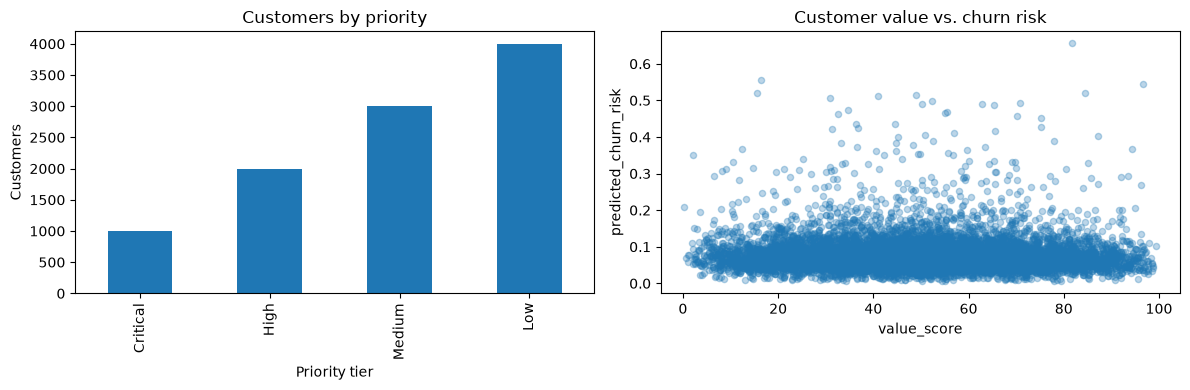

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = ['Critical', 'High', 'Medium', 'Low']
df['priority_tier'].value_counts().reindex(order).plot(kind='bar', ax=axes[0], title='Customers by priority')
axes[0].set_xlabel('Priority tier')
axes[0].set_ylabel('Customers')

df.plot.scatter(x='value_score', y='predicted_churn_risk', alpha=0.3,
                ax=axes[1], title='Customer value vs. churn risk')
plt.tight_layout()
plt.show()

## 8. Export for Power BI or Streamlit

In [8]:
columns = [
    'retention_rank', 'customer_id', 'monthly_charges_clean', 'tenure_months',
    'contract_type', 'estimated_historical_revenue', 'annualized_revenue',
    'value_score', 'predicted_churn_risk', 'expected_revenue_at_risk',
    'retention_priority', 'priority_tier', 'retention_recommendation'
]
# Include churn only as a historical label for retrospective analysis.
if 'churn' in df.columns:
    df['actual_churn_ground_truth'] = df['churn']
    columns.append('actual_churn_ground_truth')

output_path.parent.mkdir(parents=True, exist_ok=True)
df[columns].to_csv(output_path, index=False)
print('Saved:', output_path)
print('Customers exported:', len(df))
display(df[columns].head())

Saved: d:\Ahmed\My Projects\telecom intelligence project\data\processed\customer_retention_priority.csv
Customers exported: 10000


,retention_rank,customer_id,monthly_charges_clean,tenure_months,contract_type,estimated_historical_revenue,annualized_revenue,value_score,predicted_churn_risk,expected_revenue_at_risk,retention_priority,priority_tier,retention_recommendation,actual_churn_ground_truth
0,1,CUST_4574,92.36,72,Yearly,6649.92,1108.32,99.4575,0.102266,113.343584,98.43375,Critical,Personal call and resolve any service issues,0
1,2,CUST_3815,85.80,69,Yearly,5920.20,1029.60,96.5775,0.545094,561.228612,98.28375,Critical,Personal call and resolve any service issues,1
2,3,CUST_5901,93.40,68,Monthly,6351.20,1120.80,96.2175,0.269929,302.536915,98.00375,Critical,Personal call and resolve any service issues,1
3,4,CUST_8741,94.12,68,Prepaid,6400.16,1129.44,96.2425,0.133699,151.004847,97.54125,Critical,Personal call and resolve any service issues,0
4,5,CUST_2151,82.27,71,Monthly,5841.17,987.24,97.8225,0.109627,108.228065,97.37625,Critical,Personal call and resolve any service issues,0


## Interpretation and limitations

- **Value score** is a transparent heuristic, **not** a predicted customer lifetime value (CLV).
- **Expected revenue at risk** is a simplified estimate and depends on probability quality.
- **Priority tiers** are based on rank and team capacity, not statistical risk cutoffs.
- If Notebook 09 has ROC-AUC near 0.5 / AP near churn prevalence, the risk ranking is unreliable. Present this as an **experimental prototype**, not a validated retention strategy.
- For genuine future customers, use a pipeline trained on past data and validate on a later period before making business decisions.